## Ticket Classification

### Load dataset

 Hugging Face Dataset - https://huggingface.co/datasets/mteb/banking77

In [1]:
# import libraries

from datasets import load_dataset, DatasetDict
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import re

from transformers import pipeline
from transformers import AutoTokenizer
from transformers import TrainingArguments, Trainer
from transformers import AutoModelForSequenceClassification, DistilBertForSequenceClassification, DistilBertModel

from sklearn.metrics import classification_report
from sklearn.metrics import confusion_matrix
from sklearn.metrics import f1_score

from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.decomposition import PCA
from collections import Counter
from sklearn.feature_extraction.text import ENGLISH_STOP_WORDS

In [2]:
# control content display
pd.set_option("display.max_rows", None)
pd.set_option("display.max_columns", None)

In [3]:
bank_df = load_dataset("mteb/banking77")
bank_df

README.md: 0.00B [00:00, ?B/s]

data/train-00000-of-00001.parquet:   0%|          | 0.00/294k [00:00<?, ?B/s]

data/test-00000-of-00001.parquet:   0%|          | 0.00/91.4k [00:00<?, ?B/s]

Generating train split:   0%|          | 0/9993 [00:00<?, ? examples/s]

Generating test split:   0%|          | 0/3076 [00:00<?, ? examples/s]

DatasetDict({
    train: Dataset({
        features: ['text', 'label', 'label_text'],
        num_rows: 9993
    })
    test: Dataset({
        features: ['text', 'label', 'label_text'],
        num_rows: 3076
    })
})

In [4]:
test_df = bank_df["test"].to_pandas()
train_df = bank_df["train"].to_pandas()

train_df.head()

,text,label,label_text
0,I am still waiting on my card?,11,card_arrival
1,What can I do if my card still hasn't arrived ...,11,card_arrival
2,I have been waiting over a week. Is the card s...,11,card_arrival
3,Can I track my card while it is in the process...,11,card_arrival
4,"How do I know if I will get my card, or if it ...",11,card_arrival


In [5]:
# all the intent categories
label_category = train_df[['label', 'label_text']].drop_duplicates().sort_values('label').reset_index(drop=True)
label_category.head()

,label,label_text
0,0,activate_my_card
1,1,age_limit
2,2,apple_pay_or_google_pay
3,3,atm_support
4,4,automatic_top_up


### Exploratory Analysis

In [6]:
# check duplicate
train_df["text"].duplicated().sum()

np.int64(0)

In [7]:
# data info
train_df["label"].value_counts().describe()

count     77.000000
mean     129.779221
std       32.974321
min       35.000000
25%      111.000000
50%      127.000000
75%      158.000000
max      187.000000
Name: count, dtype: float64

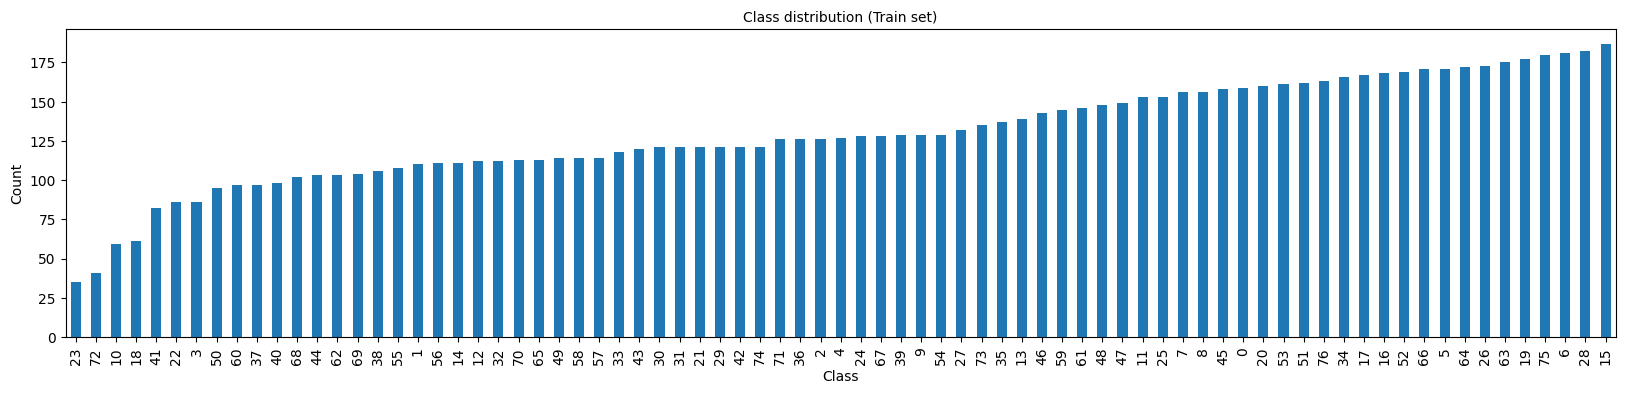

In [8]:
# class distribution - number/count of ticket in each category
train_df["label"].value_counts().sort_values().plot(kind="bar", figsize=(20,4))
plt.title("Class distribution (Train set)", fontsize=10)
plt.xlabel("Class")
plt.ylabel("Count")
plt.show()

In [9]:
# words check
for label in sorted(train_df["label"].unique())[:5]:
    print(f"\nClass {label}")
    print(train_df[train_df["label"] == label]["text"].sample(5).values)


Class 0
['I need to activate my card.' 'Show me how to activate my card'
 'What is the process for activating a new card.'
 'I would like to activate my card what do I need to do?'
 'Can I call to get my card activated?']

Class 1
['Would I be able to open an account for my daughter?'
 'I want to open an account for my children'
 'Am I allowed to get an account for my daughter?'
 'What is your age limit?' 'Is there an age limit to open an account']

Class 2
['Is it possible for me to top up with Google Pay?'
 'Can I top up using my apple watch?' "Google Pay Top up isn't working"
 'Can I top-up via Apple Pay?'
 'What should I do to top up using my Apple Watch?']

Class 3
['What ATM machines allow this card?' 'How many ATMs will take this card?'
 'what are the locations i can withdraw money'
 'What ATM accepts Mastercard?' 'Where is an ATM?']

Class 4
['Can I auto-top up?  How do I do it?'
 'What are the maximum amount you can do for auto top-up?'
 'When traveling, is it possible for it

In [10]:
# number of words in each text - length analysis
train_df["text_length"] = train_df["text"].apply(lambda x: len(x.split()))
train_df["text_length"].describe()

count    9993.000000
mean       11.955369
std         7.891187
min         3.000000
25%         7.000000
50%        10.000000
75%        13.000000
max        79.000000
Name: text_length, dtype: float64

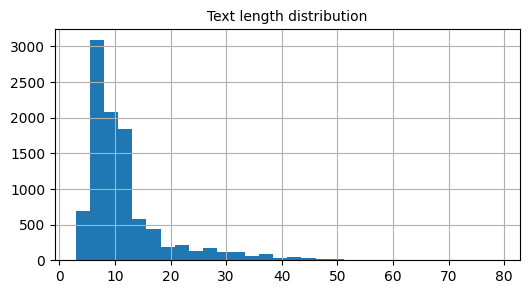

In [11]:
train_df["text_length"].hist(bins=30, figsize=(6,3))
plt.title("Text length distribution", fontsize=10)
plt.show()

In [12]:
# to check worded text, outliers
train_df.sort_values("text_length", ascending=False).head()

,text,label,label_text,text_length
3914,Hearing back from us regarding your important ...,68,unable_to_verify_identity,79
7301,Hi! I'm a university student studying abroad a...,64,transfer_fee_charged,78
3931,Hearing about your verification results from u...,68,unable_to_verify_identity,75
3902,You will hear back from us about your verifica...,68,unable_to_verify_identity,70
3907,It can take between 10 minutes to an hour befo...,68,unable_to_verify_identity,70


In [13]:
# freqently ocurring words counts
words = " ".join(train_df["text"]).lower()
# remove punctuations
all_words = re.findall(r"\b[a-zA-Z']+\b", words)
Counter(all_words).most_common(10)

[('i', 8318),
 ('my', 5682),
 ('to', 4034),
 ('a', 3564),
 ('the', 3497),
 ('card', 2673),
 ('is', 2376),
 ('do', 1848),
 ('it', 1847),
 ('can', 1844)]

#### Most frequest words, excluding stop words

In [14]:
# exclude stop words
filtered_words = [words for words in all_words if words not in ENGLISH_STOP_WORDS]
common_words = Counter(filtered_words).most_common(20)

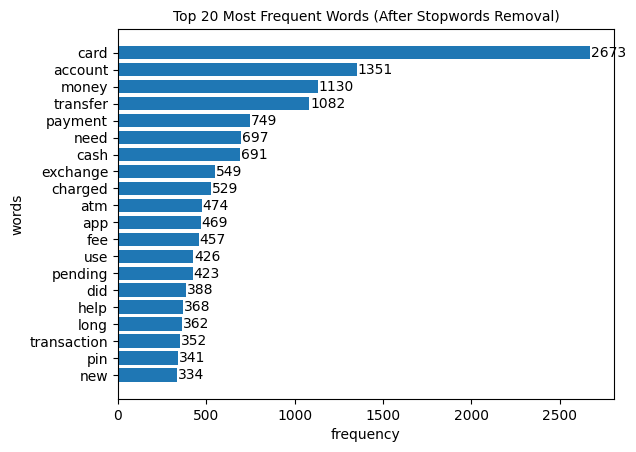

In [15]:
word_df = pd.DataFrame(common_words, columns=["words", "frequency"])
plt.figsize=(12,8)
bars = plt.barh(word_df["words"][::-1], word_df["frequency"][::-1])

for bar in bars:
    plt.text(bar.get_width() +5,
        bar.get_y() + bar.get_height()/2,
        int(bar.get_width()),
        va="center"
)

plt.title("Top 20 Most Frequent Words (After Stopwords Removal)", fontsize=10)
plt.xlabel("frequency")
plt.ylabel("words")
plt.show()

#### TF-IDF vectorisation

In [16]:
# convert features to numeric
vec = TfidfVectorizer(max_features=500)
X = vec.fit_transform(train_df["text"])

#### Principle Component Analysis 

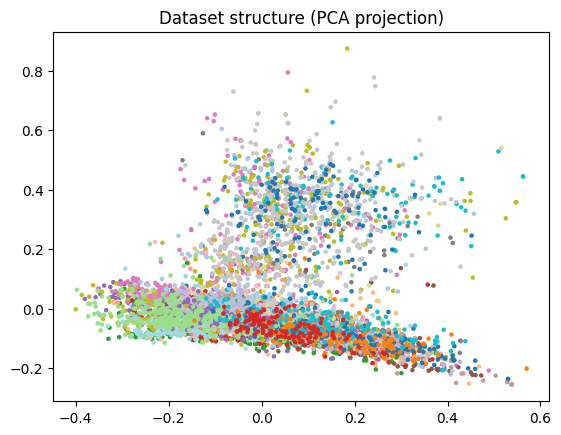

In [17]:
# dimensionality reduction: Principle Component Analaysis
X_reduced = PCA(n_components=2).fit_transform(X.toarray())

plt.scatter(X_reduced[:,0], X_reduced[:,1], c=train_df["label"], cmap="tab20", s=5)
plt.title("Dataset structure (PCA projection)")
plt.show()

### Tokenization

In [18]:
# load tokenizer
name = "distilbert/distilbert-base-uncased"
tokenizer = AutoTokenizer.from_pretrained(name)

config.json:   0%|          | 0.00/483 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/48.0 [00:00<?, ?B/s]

vocab.txt: 0.00B [00:00, ?B/s]

tokenizer.json: 0.00B [00:00, ?B/s]

In [19]:
# Prepare the dataset - this tokenizes the dataset in batches of 16 examples.
bank_tokenized = bank_df.map(
    lambda example: tokenizer(example['text'], 
                              padding=True, 
                              truncation=True, 
                              max_length=64), 
    batched=True, batch_size=16
)

bank_tokenized = bank_tokenized.remove_columns(["text", "label_text"])
bank_tokenized = bank_tokenized.rename_column("label", "labels")
bank_tokenized.set_format("torch")

Map:   0%|          | 0/9993 [00:00<?, ? examples/s]

Map:   0%|          | 0/3076 [00:00<?, ? examples/s]

In [20]:
bank_tokenized['train'][0:2]

{'labels': tensor([11, 11]),
 'input_ids': tensor([[ 101, 1045, 2572, 2145, 3403, 2006, 2026, 4003, 1029,  102,    0,    0,
             0,    0,    0,    0,    0,    0,    0,    0,    0,    0,    0],
         [ 101, 2054, 2064, 1045, 2079, 2065, 2026, 4003, 2145, 8440, 1005, 1056,
          3369, 2044, 1016, 3134, 1029,  102,    0,    0,    0,    0,    0]]),
 'token_type_ids': tensor([[0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0],
         [0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0]]),
 'attention_mask': tensor([[1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0],
         [1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 0, 0, 0, 0, 0]])}

### Fine-tune with HuggingFace Trainer

In [21]:
model = DistilBertForSequenceClassification.from_pretrained('distilbert-base-uncased', num_labels=77)

arguments = TrainingArguments(
    output_dir="banking77_trainer",
    per_device_train_batch_size=16,
    per_device_eval_batch_size=16,
    num_train_epochs=8,
    eval_strategy="epoch", # run validation at the end of each epoch
    save_strategy="epoch",
    weight_decay=0.01,
    learning_rate=2e-5,
    load_best_model_at_end=True,
    seed=224
)


config.json:   0%|          | 0.00/483 [00:00<?, ?B/s]

model.safetensors:   0%|          | 0.00/268M [00:00<?, ?B/s]

Loading weights:   0%|          | 0/100 [00:00<?, ?it/s]

DistilBertForSequenceClassification LOAD REPORT from: distilbert-base-uncased
Key                     | Status     | 
------------------------+------------+-
vocab_transform.bias    | UNEXPECTED | 
vocab_layer_norm.weight | UNEXPECTED | 
vocab_projector.bias    | UNEXPECTED | 
vocab_layer_norm.bias   | UNEXPECTED | 
vocab_transform.weight  | UNEXPECTED | 
classifier.weight       | MISSING    | 
pre_classifier.weight   | MISSING    | 
classifier.bias         | MISSING    | 
pre_classifier.bias     | MISSING    | 

Notes:
- UNEXPECTED	:can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING	:those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


In [22]:
def compute_metrics(eval_pred):
    """Called at the end of validation. Gives accuracy"""
    logits, labels = eval_pred
    predictions = np.argmax(logits, axis=-1)
    
    # calculates the accuracy and f1-score
    acc = np.mean(predictions == labels)
    f1 = f1_score(labels, predictions, average='macro')
    return {"accuracy": acc, "f1_macro": f1}


In [23]:
# split train into train/val

from sklearn.metrics import f1_score
import numpy as np

split = bank_tokenized['train'].train_test_split(test_size=0.1, seed=224)
                                                # stratify_by_column="labels")
train_dataset = split['train']   # 90% of original train
val_dataset = split['test']      # 10% of original train 


trainer = Trainer(
    model=model,
    args=arguments,
    train_dataset=train_dataset,
    eval_dataset=val_dataset, 
    processing_class=tokenizer,
    compute_metrics=compute_metrics
)


In [24]:
# train the model
trainer.train()

/usr/local/lib/python3.12/dist-packages/torch/autograd/function.py:583: UserWarning: Was asked to gather along dimension 0, but all input tensors were scalars; will instead unsqueeze and return a vector.
  return super().apply(*args, **kwargs)  # type: ignore[misc]


Epoch,Training Loss,Validation Loss,Accuracy,F1 Macro
1,No log,5.148063,0.620000,0.545580
2,5.965998,2.680846,0.823000,0.755998
3,5.965998,1.577282,0.856000,0.811910
4,2.172741,1.084098,0.891000,0.879798
5,2.172741,0.868401,0.899000,0.892867
6,1.014705,0.762855,0.912000,0.907286
7,1.014705,0.716584,0.909000,0.906246
8,0.622488,0.695700,0.911000,0.906798


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

/usr/local/lib/python3.12/dist-packages/torch/autograd/function.py:583: UserWarning: Was asked to gather along dimension 0, but all input tensors were scalars; will instead unsqueeze and return a vector.
  return super().apply(*args, **kwargs)  # type: ignore[misc]


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

/usr/local/lib/python3.12/dist-packages/torch/autograd/function.py:583: UserWarning: Was asked to gather along dimension 0, but all input tensors were scalars; will instead unsqueeze and return a vector.
  return super().apply(*args, **kwargs)  # type: ignore[misc]


... (9 outputs left out)

/usr/local/lib/python3.12/dist-packages/torch/autograd/function.py:583: UserWarning: Was asked to gather along dimension 0, but all input tensors were scalars; will instead unsqueeze and return a vector.
  return super().apply(*args, **kwargs)  # type: ignore[misc]


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

There were missing keys in the checkpoint model loaded: ['distilbert.embeddings.LayerNorm.weight', 'distilbert.embeddings.LayerNorm.bias'].
There were unexpected keys in the checkpoint model loaded: ['distilbert.embeddings.LayerNorm.beta', 'distilbert.embeddings.LayerNorm.gamma'].


TrainOutput(global_step=2256, training_loss=2.223863331138665, metrics={'train_runtime': 357.1445, 'train_samples_per_second': 201.442, 'train_steps_per_second': 6.317, 'total_flos': 1166663194102062.0, 'train_loss': 2.223863331138665, 'epoch': 8.0})

### Evaluation

In [25]:
test_dataset = bank_tokenized['test']

predictions = trainer.predict(test_dataset)

y_pred = predictions.predictions.argmax(axis=1)
y_true = predictions.label_ids

print(classification_report(y_true, y_pred))

/usr/local/lib/python3.12/dist-packages/torch/autograd/function.py:583: UserWarning: Was asked to gather along dimension 0, but all input tensors were scalars; will instead unsqueeze and return a vector.
  return super().apply(*args, **kwargs)  # type: ignore[misc]


              precision    recall  f1-score   support

           0       1.00      0.97      0.99        40
           1       0.98      1.00      0.99        40
           2       1.00      1.00      1.00        40
           3       1.00      0.97      0.99        39
           4       0.97      0.93      0.95        40
           5       0.82      0.80      0.81        40
           6       0.97      0.95      0.96        40
           7       0.97      0.88      0.92        40
           8       1.00      0.93      0.96        40
           9       0.95      0.95      0.95        40
          10       1.00      0.80      0.89        40
          11       0.85      0.85      0.85        40
          12       0.86      0.90      0.88        40
          13       0.87      0.97      0.92        40
          14       0.87      0.97      0.92        40
          15       0.78      0.95      0.85        40
          16       0.90      0.90      0.90        40
          17       0.92    

In [26]:
# checks
train_df[train_df['label'] == 53]  
# why_verify_identity, topping_up_by_card, verify_my_identity, pending_transfer, reverted_card_payment?, 

,text,label,label_text,text_length
6714,I wanted to purchase something online but the ...,53,reverted_card_payment?,32
6715,"I tried to use my debit card, but the payment ...",53,reverted_card_payment?,13
6716,"Hi, I had an issue with my card payment and It...",53,reverted_card_payment?,53
6717,I think my card payment has been reverted,53,reverted_card_payment?,8
6718,Tell me why my card payment would be reverted.,53,reverted_card_payment?,9
6719,Why has my card payment been reversed?,53,reverted_card_payment?,7
6720,I didn't cancel my card payment.,53,reverted_card_payment?,6
6721,Can you tell me why the card payment came back?,53,reverted_card_payment?,10
6722,How come the money from the merchant appeared ...,53,reverted_card_payment?,12
6723,My payment was terminated,53,reverted_card_payment?,4


In [27]:
# top 10 classes
top10_classes = np.argsort(np.bincount(y_true))[-10:]

# filter data
mask = np.isin(y_true, top10_classes)
y_true_10 = np.array(y_true)[mask]
y_pred_10 = np.array(y_pred)[mask]

In [28]:
# remap labels
label_map = {old: i for i, old in enumerate(top10_classes)}

y_true_mapped = np.array([label_map[y] for y in y_true_10])
y_pred_mapped = np.array([label_map.get(y, -1) for y in y_pred_10])

In [29]:
# confusion matrix
cm_10 = confusion_matrix(y_true_mapped, y_pred_mapped)

In [30]:
# normalize - removes nan
cm_10_norm = cm_10.astype(float) / np.maximum(cm_10.sum(axis=1, keepdims=True), 1)

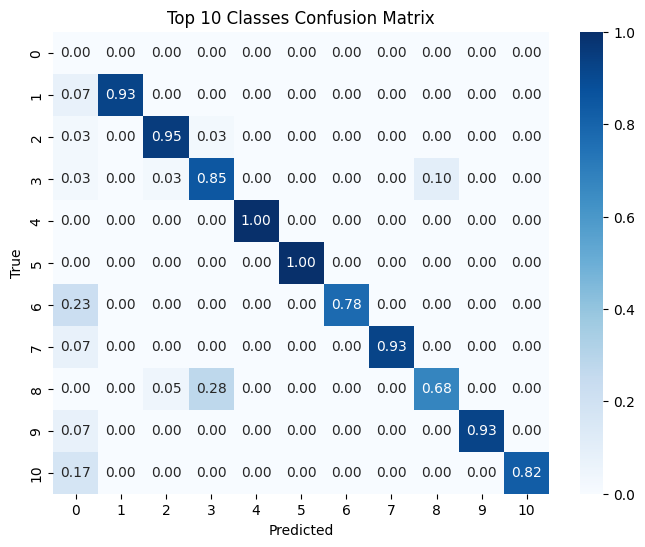

In [31]:
plt.figure(figsize=(8,6))

sns.heatmap(
    cm_10_norm,
    annot=True,
    cmap="Blues",
    fmt=".2f"
)

plt.title("Top 10 Classes Confusion Matrix")
plt.xlabel("Predicted")
plt.ylabel("True")

plt.show()

In [32]:
sample_df = test_df
sample_df["actual"] = sample_df["label"]
sample_df["predicted"] = y_pred

In [33]:
label_map = (
    sample_df[["label", "label_text"]]
    .drop_duplicates()
    .set_index("label")["label_text"]
    .to_dict()
)

In [34]:
sample_df["actual_intent"] = sample_df["actual"].map(label_map)
sample_df["predicted_intent"] = sample_df["predicted"].map(label_map)

In [35]:
errors_df = sample_df[
    sample_df["actual"] != sample_df["predicted"]
]

errors_df = errors_df.sample(
    min(10, len(errors_df)),
    random_state=42
)

errors_df[
    [
        "text",
        "actual_intent",
        "predicted_intent"
    ]
]

,text,actual_intent,predicted_intent
2101,"There must be an issue, why has my card been c...",reverted_card_payment?,lost_or_stolen_card
1345,Cannot access my top up.,topping_up_by_card,top_up_failed
1516,Why was my account deducted from a seller when...,direct_debit_payment_not_recognised,reverted_card_payment?
2521,Why is my virtual card is being declined?,virtual_card_not_working,getting_virtual_card
598,Should i reinstall the payment app?,contactless_not_working,reverted_card_payment?
2913,"When I got cash, I'm pretty sure there was a g...",cash_withdrawal_charge,wrong_exchange_rate_for_cash_withdrawal
1686,I wasn't charged the correct amount for an ite...,request_refund,card_payment_fee_charged
1330,how can i top up?,topping_up_by_card,top_up_limits
1172,What is the purpose for the identity check,why_verify_identity,verify_my_identity
1018,What happened to my top-up?,top_up_reverted,pending_top_up


In [36]:
results = trainer.evaluate()
results

/usr/local/lib/python3.12/dist-packages/torch/autograd/function.py:583: UserWarning: Was asked to gather along dimension 0, but all input tensors were scalars; will instead unsqueeze and return a vector.
  return super().apply(*args, **kwargs)  # type: ignore[misc]


{'eval_loss': 0.6957001090049744,
 'eval_accuracy': 0.911,
 'eval_f1_macro': 0.9067981828845951,
 'eval_runtime': 1.7265,
 'eval_samples_per_second': 579.203,
 'eval_steps_per_second': 18.534,
 'epoch': 8.0}

In [37]:
# predict intent

clf = pipeline(
    "text-classification",
    model=trainer.model,
    tokenizer=tokenizer
)

text = "my account is locked"
pred = clf(text)[0]

pred_id = int(pred["label"].split("_")[1])

print("Text:", text)
print("Prediction:", label_map[pred_id])
print("Confidence:", pred["score"])

Text: my account is locked
Prediction: terminate_account
Confidence: 0.7410513758659363
